<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/06_pytorch_transfer_learning_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Food Image Classification with PyTorch

## Project Overview

This project explores transfer learning for multi-class food image classification using PyTorch and pretrained convolutional neural networks.

The goal is to classify food images into three categories:
- Pizza
- Steak
- Sushi

## Objectives
- Implement transfer learning using EfficientNet-B0 and ResNet.
- Evaluate model performance using accuracy and a confusion matrix.
- Analyze incorrectly classified images.
- Compare model performance with different training dataset sizes.

## Tech Stack
Python, PyTorch, Torchvision, NumPy, Pandas, Matplotlib, Scikit-learn.

* These solutions are based on [section 06. PyTorch Transfer Learning](https://www.learnpytorch.io/06_pytorch_transfer_learning/) of the Learn PyTorch for Deep Learning course by Zero to Mastery.

## 1. Make predictions on the entire test dataset and plot a confusion matrix for the results of the model compared to the truth labels.


In [1]:
!pip install torchinfo

In [2]:
# Import required libraries/code
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm

from torch import nn
from torchvision import transforms, datasets
from torchinfo import summary

# Try to get torchinfo, install it if it doesn't work
try:
    from torchinfo import summary
except:
    print("[INFO] Couldn't find torchinfo... installing it.")
    !pip install -q torchinfo
    from torchinfo import summary

# Try to import the going_modular directory, download it from GitHub if it doesn't work
try:
    from going_modular.going_modular import data_setup, engine
except:
    print("[INFO] Couldn't find going_modular scripts... downloading them from GitHub.")
    !git clone https://github.com/mrdbourke/pytorch-deep-learning
    !mv pytorch-deep-learning/going_modular .
    !rm -rf pytorch-deep-learning
    from going_modular.going_modular import data_setup, engine

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

### Get data

In [4]:
import os
import requests
import zipfile

from pathlib import Path

# Setup path to data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

# If the image folder doesn't exist, download it and prepare it...
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)

    # Download pizza, steak, sushi data
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    # Unzip pizza, steak, sushi data
    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("Unzipping pizza, steak, sushi data...")
        zip_ref.extractall(image_path)

    # Remove .zip file
    os.remove(data_path / "pizza_steak_sushi.zip")

# Setup Dirs
train_dir = image_path / "train"
test_dir = image_path / "test"

data/pizza_steak_sushi directory exists.


### Prepare data

In [5]:
# Create a transforms pipeline
simple_transform = transforms.Compose([
    transforms.Resize((224, 224)), # 1. Reshape all images to 224x224
    transforms.ToTensor(), # 2. Turn image values to between 0 & 1
    transforms.Normalize(mean=[0.485, 0.456, 0.406], # 3. A mean of [0.485, 0.456, 0.406] (across each colour channel)
                         std=[0.229, 0.224, 0.225]) # 4. A standard deviation of [0.229, 0.224, 0.225] (across each colour channel),
])

In [6]:
# Create training and testing DataLoader's as well as get a list of class names
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                               test_dir=test_dir,
                                                                               transform=simple_transform, # resize, convert images to between 0 & 1 and normalize them
                                                                               batch_size=32) # set mini-batch size to 32
class_to_idx = train_dataloader.dataset.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}

print(class_to_idx)

{'pizza': 0, 'steak': 1, 'sushi': 2}


### Get and prepare a pretrained model

In [7]:
# Setup the model with pretrained weights and send it to the target device
model_0 = torchvision.models.efficientnet_b0(pretrained=True).to(device)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [8]:
# Freeze all base layers in the "features" section of the model (the feature extractor) by setting requires_grad=False
for param in model_0.features.parameters():
    param.requires_grad = False

In [9]:
# Set the manual seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Get the length of class_names (one output unit for each class)
output_shape = len(class_names)

# Recreate the classifier layer and seed it to the target device
model_0.classifier = torch.nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True),
    torch.nn.Linear(in_features=1280,
                    out_features=output_shape, # same number of output units as our number of classes
                    bias=True)).to(device)

### Train model

In [10]:
# Define loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_0.parameters(), lr=0.001)

In [11]:
y_list = []
for batch, (X, y) in enumerate(test_dataloader):
            for i in y:
              y_list.append(i)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [12]:
img, label = next(iter(test_dataloader))

print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape}")

Image shape: torch.Size([32, 3, 224, 224]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([32])


In [13]:
# Set the random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Setup training and save the results
model_0_results = engine.train(model=model_0,
                       train_dataloader=train_dataloader,
                       test_dataloader=test_dataloader,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epochs=5,
                       device=device)
efficientnet_b0_accuracy_0 = model_0_results["test_acc"][-1]
end_time = timer()
print(f"[INFO] Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0963 | train_acc: 0.3984 | test_loss: 0.8989 | test_acc: 0.5597
Epoch: 2 | train_loss: 0.9230 | train_acc: 0.6680 | test_loss: 0.8171 | test_acc: 0.7131
Epoch: 3 | train_loss: 0.7851 | train_acc: 0.7539 | test_loss: 0.6707 | test_acc: 0.9072
Epoch: 4 | train_loss: 0.7408 | train_acc: 0.7109 | test_loss: 0.6582 | test_acc: 0.8759
Epoch: 5 | train_loss: 0.6206 | train_acc: 0.7773 | test_loss: 0.6028 | test_acc: 0.9072
[INFO] Total training time: 202.360 seconds


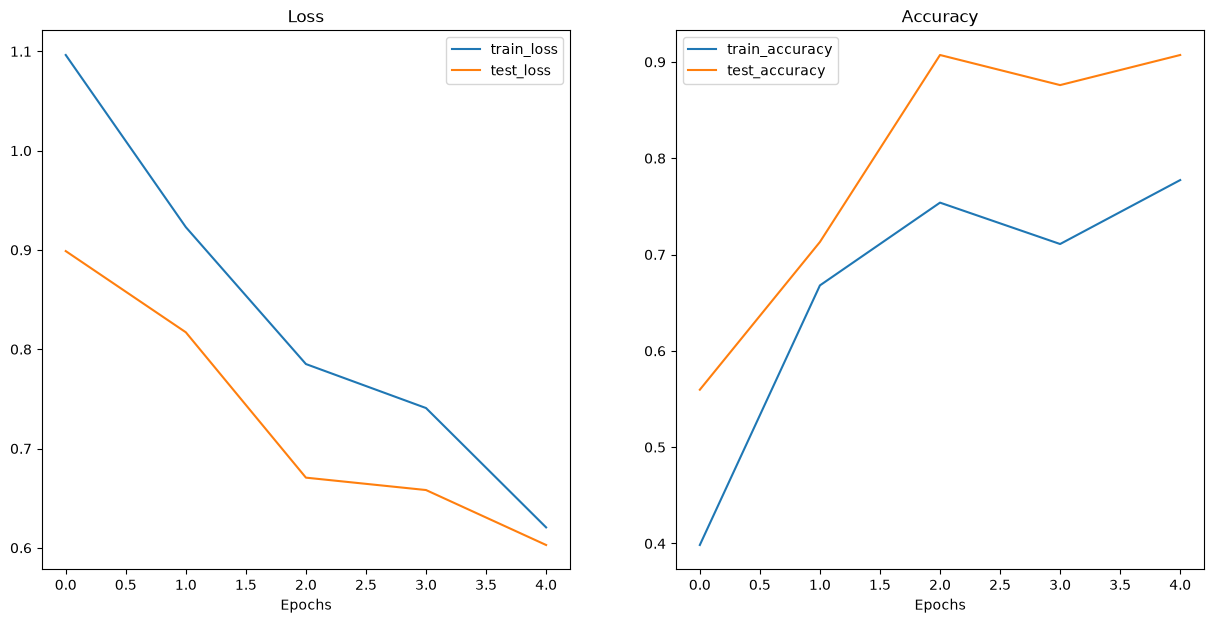

In [14]:
# Get the plot_loss_curves() function
try:
    from helper_functions import plot_loss_curves
except:
    print("[INFO] Couldn't find helper_functions.py, downloading...")
    with open("helper_functions.py", "wb") as f:
        import requests
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
        f.write(request.content)
    from helper_functions import plot_loss_curves

# Plot the loss curves of our model
plot_loss_curves(model_0_results)


### Make predictions on the entire test dataset with the model

In [15]:
from typing import List, Tuple

from PIL import Image

# 1. Take in a trained model, class names, image path, image size, a transform and target device
def pred_and_plot_image(model: torch.nn.Module,
                        image_path: str,
                        class_names: List[str],
                        image_size: Tuple[int, int] = (224, 224),
                        transform: torchvision.transforms = None,
                        device: torch.device=device):


    # 2. Open image
    img = Image.open(image_path)

    # 3. Create transformation for image
    if transform is not None:
        image_transform = transform
    else:
        image_transform = transforms.Compose([
            transforms.Resize(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225]),
        ])

    ### Predict on image ###

    # 4. Make sure the model is on the target device
    model.to(device)

    # 5. Turn on model evaluation mode and inference mode
    model.eval()
    with torch.inference_mode():
      # 6. Transform and add an extra dimension to image (model requires samples in [batch_size, color_channels, height, width])
      transformed_image = image_transform(img).unsqueeze(dim=0)

      # 7. Make a prediction on image with an extra dimension and send it to the target device
      target_image_pred = model(transformed_image.to(device))

    # 8. Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # 9. Convert prediction probabilities -> prediction labels
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    # 10. Plot image with predicted label and probability
    plt.figure()
    plt.imshow(img)
    plt.title(f"Pred: {class_names[target_image_pred_label]} | Prob: {target_image_pred_probs.max():.3f}")
    plt.axis(False);

In [16]:
image_size = (224, 224)
image_transform = transforms.Compose([
            transforms.Resize(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225]),
])


test_image_path_list = list(Path(test_dir).glob("*/*.jpg")) # get list all image paths from test data
y_preds = []
y_labels = []
model_0.to(device)

for img_path in tqdm(test_image_path_list, desc="Making predictions"):
    model_0.eval()
    with torch.inference_mode():

        img = Image.open(img_path)
        transformed_image = image_transform(img).unsqueeze(dim=0)

        target_image_pred = model_0(transformed_image.to(device))

    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    y_preds.append(target_image_pred_probs.cpu())
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)
    y_labels.append(target_image_pred_label.cpu())

y_pred_tensor = torch.cat(y_preds)
y_labels_tensor = torch.cat(y_labels)


Making predictions:   0%|          | 0/75 [00:00<?, ?it/s]

### Make a confusion matrix with the test preds and the truth labels

In [18]:
import re

pattern = r"^data/pizza_steak_sushi/test/([^/]+)/\d+\.jpg$"

In [ ]:
labels_list = []
for image_path in test_image_path_list:
    image_path = str(image_path)
    match = re.search(pattern, image_path)
    if match:
        label = match.group(1)
        labels_list.append(label)

In [21]:
#labels_list
# pizza - 0, steak - 1, sushi - 2
target_tensor = torch.tensor([
    class_to_idx[label] for label in labels_list
])
target_tensor

tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0])

In [23]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix


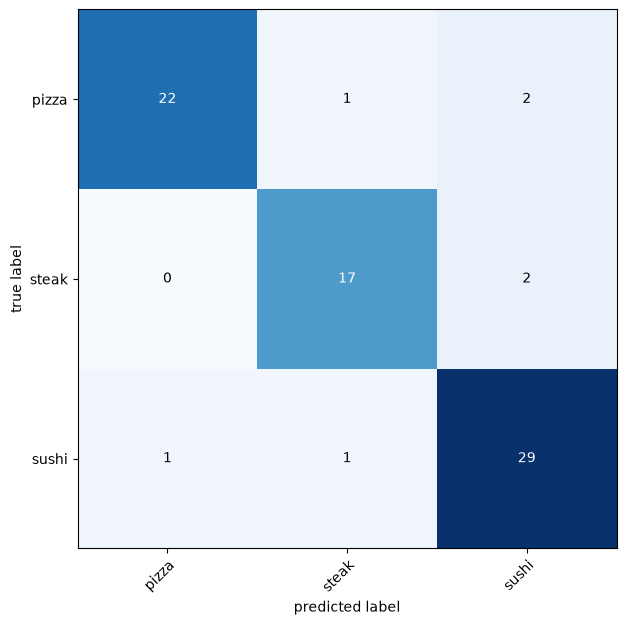

In [25]:
# Setup confusion matrix instance and compare predictions to targets
confmat = ConfusionMatrix(num_classes=len(class_names), task='multiclass')
confmat_tensor = confmat(preds=y_labels_tensor,
                         target=target_tensor)

fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    class_names=class_names,
    figsize=(10, 7)
);

## 2. Get the "most wrong" of the predictions on the test dataset and plot the 5 "most wrong" images.

In [27]:
probs, indices = torch.max(y_pred_tensor, dim=1)

tensor([0.8306, 0.6801, 0.3376, 0.7438, 0.4941, 0.7926, 0.6834, 0.7847, 0.7366,
        0.6941, 0.8655, 0.6635, 0.7369, 0.5798, 0.9015, 0.7437, 0.6154, 0.4106,
        0.4685, 0.4811, 0.4341, 0.4993, 0.5133, 0.5497, 0.4622, 0.5721, 0.6052,
        0.4413, 0.5415, 0.4682, 0.4718, 0.8019, 0.5934, 0.7741, 0.5176, 0.4541,
        0.5749, 0.6311, 0.5292, 0.5234, 0.7808, 0.4316, 0.6250, 0.4251, 0.4507,
        0.8010, 0.5104, 0.6936, 0.4369, 0.4888, 0.5439, 0.7381, 0.5435, 0.4126,
        0.5678, 0.6678, 0.8172, 0.4160, 0.6671, 0.6090, 0.7447, 0.5831, 0.3634,
        0.7686, 0.4982, 0.7351, 0.6564, 0.4617, 0.4420, 0.4653, 0.8098, 0.7245,
        0.4988, 0.4082, 0.6300])

In [28]:
from pathlib import Path

path_1 = "data/pizza_steak_sushi/test/steak/966174.jpg"
path_1 = Path(path_1)

'steak'

In [29]:
df = pd.DataFrame({"sample": test_image_path_list, "label": target_tensor, "prediction": y_labels_tensor, "pred_prob": probs})
df.head()

,sample,label,prediction,pred_prob
0,data/pizza_steak_sushi/test/steak/1302563.jpg,1,1,0.830568
1,data/pizza_steak_sushi/test/steak/2117351.jpg,1,1,0.680150
2,data/pizza_steak_sushi/test/steak/1627703.jpg,1,1,0.337603
3,data/pizza_steak_sushi/test/steak/502076.jpg,1,1,0.743822
4,data/pizza_steak_sushi/test/steak/27415.jpg,1,2,0.494144
...,...,...,...,...
70,data/pizza_steak_sushi/test/pizza/1925494.jpg,0,0,0.809819
71,data/pizza_steak_sushi/test/pizza/398345.jpg,0,0,0.724481
72,data/pizza_steak_sushi/test/pizza/648055.jpg,0,0,0.498845
73,data/pizza_steak_sushi/test/pizza/309892.jpg,0,2,0.408191


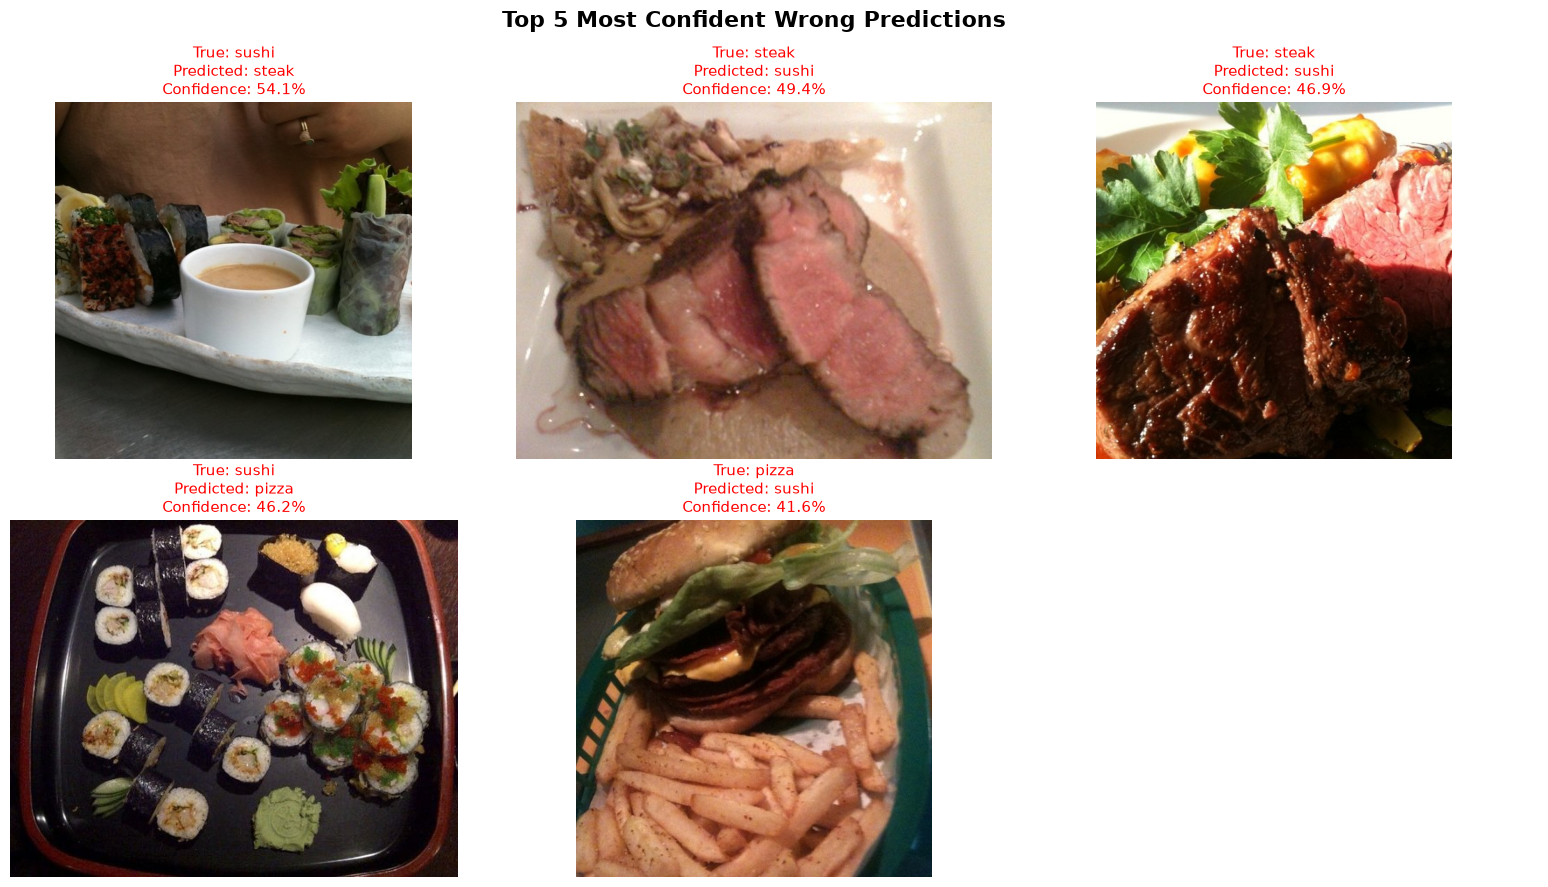

In [30]:
# Get the 5 most confident incorrect predictions
most_wrong = (df[df["label"] != df["prediction"]].sort_values(by="pred_prob", ascending=False).head(5))

# Create a figure with 5 subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (_, row) in zip(axes, most_wrong.iterrows()):

    img = Image.open(row["sample"]).convert("RGB")

    # Get true and predicted labels
    true_label = class_names[int(row["label"])]
    pred_label = class_names[int(row["prediction"])]
    confidence = float(row["pred_prob"])

    # Plot image
    ax.imshow(img)
    ax.set_title(
        f"True: {true_label}\n"
        f"Predicted: {pred_label}\n"
        f"Confidence: {confidence:.1%}",
        fontsize=11,
        color="red"
    )
    ax.axis("off")

# Hide unused subplot
for ax in axes[len(most_wrong):]:
    ax.axis("off")

plt.suptitle(
    "Top 5 Most Confident Wrong Predictions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


## 3. Predict on your own image of pizza

In [31]:
# Get an image of pizza
!wget https://images.unsplash.com/photo-1588315029754-2dd089d39a1a
!cp photo-1588315029754-2dd089d39a1a pizza.jpg


--2026-11-18 17:53:07--  https://images.unsplash.com/photo-1588315029754-2dd089d39a1a
Resolving images.unsplash.com (images.unsplash.com)... 151.101.2.208, 151.101.66.208, 151.101.130.208, ...
Connecting to images.unsplash.com (images.unsplash.com)|151.101.2.208|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3208960 (3.1M) [image/jpeg]
Saving to: ‘photo-1588315029754-2dd089d39a1a’

photo-1588315029754 100%[===================>]   3.06M  --.-KB/s    in 0.07s   

2026-11-18 17:53:07 (42.9 MB/s) - ‘photo-1588315029754-2dd089d39a1a’ saved [3208960/3208960]



In [32]:
pizza_img = Image.open('pizza.jpg')
transformed_image = image_transform(pizza_img).unsqueeze(dim=0)
target_image_pred = model_0(transformed_image.to(device))
target_image_pred_probs = torch.softmax(target_image_pred, dim=1)
target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)
print(target_image_pred_label)

tensor([2])


## 4. Train the model for longer (10 epochs)

In [34]:
# Setup the model with pretrained weights and send it to the target device
model_1 = torchvision.models.efficientnet_b0(pretrained=True).to(device)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [35]:
# Freeze all base layers in the "features" section of the model (the feature extractor) by setting requires_grad=False
for param in model_1.features.parameters():
    param.requires_grad = False

In [36]:
# Set the manual seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Get the length of class_names (one output unit for each class)
output_shape = len(class_names)

# Recreate the classifier layer and seed it to the target device
model_1.classifier = torch.nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True),
    torch.nn.Linear(in_features=1280,
                    out_features=output_shape, # same number of output units as our number of classes
                    bias=True)).to(device)

In [37]:
# Define loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1.parameters(), lr=0.001)

In [38]:
# Recreate a new model

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Setup training and save the results
model_1_results = engine.train(model=model_1,
                       train_dataloader=train_dataloader,
                       test_dataloader=test_dataloader,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epochs=10,
                       device=device)
efficientnet_b0_accuracy_1 = model_1_results["train_acc"][-1]

end_time = timer()
print(f"[INFO] Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch: 1 | train_loss: 1.0497 | train_acc: 0.4453 | test_loss: 0.9296 | test_acc: 0.4470
Epoch: 2 | train_loss: 0.9335 | train_acc: 0.5234 | test_loss: 0.8193 | test_acc: 0.6411
Epoch: 3 | train_loss: 0.7878 | train_acc: 0.7305 | test_loss: 0.6944 | test_acc: 0.8864
Epoch: 4 | train_loss: 0.6920 | train_acc: 0.8828 | test_loss: 0.6497 | test_acc: 0.8968
Epoch: 5 | train_loss: 0.6931 | train_acc: 0.7383 | test_loss: 0.6418 | test_acc: 0.8352
Epoch: 6 | train_loss: 0.5720 | train_acc: 0.9023 | test_loss: 0.5509 | test_acc: 0.8968
Epoch: 7 | train_loss: 0.5508 | train_acc: 0.7969 | test_loss: 0.5324 | test_acc: 0.9176
Epoch: 8 | train_loss: 0.5074 | train_acc: 0.8164 | test_loss: 0.5141 | test_acc: 0.9072
Epoch: 9 | train_loss: 0.5785 | train_acc: 0.7891 | test_loss: 0.5324 | test_acc: 0.8769
Epoch: 10 | train_loss: 0.4566 | train_acc: 0.8281 | test_loss: 0.4553 | test_acc: 0.8968
[INFO] Total training time: 378.986 seconds


## 5. Train the model with more data: 20% of the images from Food101 of Pizza, Steak and Sushi images.

### Get 20% data

In [39]:
import os
import requests
import zipfile

from pathlib import Path

# Setup path to data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi_20_percent"
image_data_zip_path = "pizza_steak_sushi_20_percent.zip"

# If the image folder doesn't exist, download it and prepare it...
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)

    # Download pizza, steak, sushi data
    with open(data_path / image_data_zip_path, "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    # Unzip pizza, steak, sushi data
    with zipfile.ZipFile(data_path / image_data_zip_path, "r") as zip_ref:
        print("Unzipping pizza, steak, sushi 20% data...")
        zip_ref.extractall(image_path)

    # Remove .zip file
    os.remove(data_path / image_data_zip_path)

# Setup Dirs
train_dir_20_percent = image_path / "train"
test_dir_20_percent = image_path / "test"

train_dir_20_percent, test_dir_20_percent

Did not find data/pizza_steak_sushi_20_percent directory, creating one...
Unzipping pizza, steak, sushi 20% data...


(PosixPath('data/pizza_steak_sushi_20_percent/train'),
 PosixPath('data/pizza_steak_sushi_20_percent/test'))

### Create DataLoaders

In [40]:
# Create a transforms pipeline
simple_transform = transforms.Compose([
    transforms.Resize((224, 224)), # 1. Reshape all images to 224x224 (though some models may require different sizes)
    transforms.ToTensor(), # 2. Turn image values to between 0 & 1
    transforms.Normalize(mean=[0.485, 0.456, 0.406], # 3. A mean of [0.485, 0.456, 0.406] (across each colour channel)
                         std=[0.229, 0.224, 0.225]) # 4. A standard deviation of [0.229, 0.224, 0.225] (across each colour channel),
])

In [41]:
# Create training and testing DataLoader's as well as get a list of class names
train_dataloader_20_percent, test_dataloader_20_percent, class_names = data_setup.create_dataloaders(train_dir=train_dir_20_percent,
                                                                                                     test_dir=test_dir_20_percent,
                                                                                                     transform=simple_transform, # resize, convert images to between 0 & 1 and normalize them
                                                                                                     batch_size=32) # set mini-batch size to 32

train_dataloader_20_percent, test_dataloader_20_percent, class_names

(<torch.utils.data.dataloader.DataLoader at 0x7e0382ba0690>,
 ['pizza', 'steak', 'sushi'])

### Get a pretrained model

In [42]:
# Setup the model with pretrained weights and send it to the target device
model_2 = torchvision.models.efficientnet_b0(pretrained=True).to(device)

# Freeze all base layers in the "features" section of the model (the feature extractor) by setting requires_grad=False
for param in model_2.features.parameters():
    param.requires_grad = False


# Set the manual seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Get the length of class_names (one output unit for each class)
output_shape = len(class_names)

# Recreate the classifier layer and seed it to the target device
model_2.classifier = torch.nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True),
    torch.nn.Linear(in_features=1280,
                    out_features=output_shape, # same number of output units as our number of classes
                    bias=True)).to(device)

# Define loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2.parameters(), lr=0.001)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


### Train a model with 20% of the data

In [43]:
# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Setup training and save the results
model_2_results = engine.train(model=model_2,
                       train_dataloader=train_dataloader_20_percent,
                       test_dataloader=test_dataloader_20_percent,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epochs=10,
                       device=device)
efficientnet_b0_accuracy_2 = model_2_results["test_acc"][-1]

end_time = timer()
print(f"[INFO] Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch: 1 | train_loss: 0.9679 | train_acc: 0.5583 | test_loss: 0.6444 | test_acc: 0.8602
Epoch: 2 | train_loss: 0.7013 | train_acc: 0.8292 | test_loss: 0.5299 | test_acc: 0.8790
Epoch: 3 | train_loss: 0.5647 | train_acc: 0.8458 | test_loss: 0.4642 | test_acc: 0.9006
Epoch: 4 | train_loss: 0.4892 | train_acc: 0.8812 | test_loss: 0.4109 | test_acc: 0.8915
Epoch: 5 | train_loss: 0.3976 | train_acc: 0.9125 | test_loss: 0.3734 | test_acc: 0.8943
Epoch: 6 | train_loss: 0.3830 | train_acc: 0.8979 | test_loss: 0.3249 | test_acc: 0.9256
Epoch: 7 | train_loss: 0.4221 | train_acc: 0.8396 | test_loss: 0.3102 | test_acc: 0.9193
Epoch: 8 | train_loss: 0.3339 | train_acc: 0.9229 | test_loss: 0.3133 | test_acc: 0.9074
Epoch: 9 | train_loss: 0.3152 | train_acc: 0.9229 | test_loss: 0.2958 | test_acc: 0.9131
Epoch: 10 | train_loss: 0.3174 | train_acc: 0.8854 | test_loss: 0.2885 | test_acc: 0.9165
[INFO] Total training time: 695.828 seconds


## 6. Try a different model from [`torchvision.models`](https://pytorch.org/vision/stable/models.html) on the Pizza, Steak, Sushi data (resnet50).

In [44]:
# Setup the model with pretrained weights and send it to the target device
model_3 = torchvision.models.resnet50(pretrained=True).to(device)

# Freeze all base layers in the "features" section of the model (the feature extractor) by setting requires_grad=False
for param in model_3.conv1.parameters():
    param.requires_grad = False

for param in model_3.bn1.parameters():
    param.requires_grad = False

for param in model_3.relu.parameters():
    param.requires_grad = False

for param in model_3.maxpool.parameters():
    param.requires_grad = False

for param in model_3.layer1.parameters():
    param.requires_grad = False

for param in model_3.layer2.parameters():
    param.requires_grad = False

for param in model_3.layer3.parameters():
    param.requires_grad = False

for param in model_3.layer4.parameters():
    param.requires_grad = False



# Set the manual seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Get the length of class_names (one output unit for each class)
output_shape = len(class_names)

# Recreate the classifier layer and seed it to the target device
model_3.fc = torch.nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True),
    torch.nn.Linear(in_features=2048,
                    out_features=output_shape, # same number of output units as our number of classes
                    bias=True)).to(device)



# Define loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_3.parameters(), lr=0.001)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 167MB/s]


In [47]:
# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Setup training and save the results
model_3_results = engine.train(model=model_3,
                       train_dataloader=train_dataloader_20_percent,
                       test_dataloader=test_dataloader_20_percent,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epochs=10,
                       device=device)
# Accuracy of the last epoch
resnet50_accuracy = model_3_results["test_acc"][-1]

end_time = timer()
print(f"[INFO] Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0014 | train_acc: 0.5437 | test_loss: 0.6979 | test_acc: 0.6898
Epoch: 2 | train_loss: 0.6788 | train_acc: 0.7167 | test_loss: 0.5565 | test_acc: 0.8187
Epoch: 3 | train_loss: 0.4649 | train_acc: 0.8896 | test_loss: 0.3972 | test_acc: 0.9290
Epoch: 4 | train_loss: 0.4061 | train_acc: 0.8792 | test_loss: 0.4098 | test_acc: 0.8886
Epoch: 5 | train_loss: 0.4798 | train_acc: 0.8396 | test_loss: 0.4043 | test_acc: 0.8688
Epoch: 6 | train_loss: 0.4057 | train_acc: 0.8521 | test_loss: 0.2908 | test_acc: 0.9125
Epoch: 7 | train_loss: 0.3595 | train_acc: 0.8771 | test_loss: 0.3160 | test_acc: 0.9227
Epoch: 8 | train_loss: 0.3247 | train_acc: 0.8792 | test_loss: 0.2935 | test_acc: 0.8983
Epoch: 9 | train_loss: 0.2933 | train_acc: 0.9167 | test_loss: 0.2520 | test_acc: 0.9313
Epoch: 10 | train_loss: 0.2781 | train_acc: 0.9396 | test_loss: 0.2673 | test_acc: 0.9227
[INFO] Total training time: 1764.756 seconds


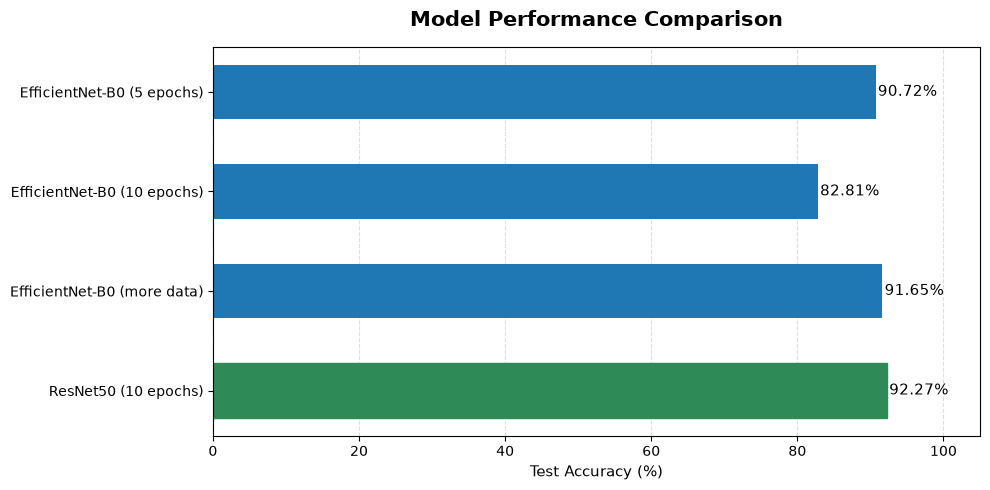

In [58]:
# Model accuracies
experiments = [
    "EfficientNet-B0 (5 epochs)",
    "EfficientNet-B0 (10 epochs)",
    "EfficientNet-B0 (more data)",
    "ResNet50 (10 epochs)"
]

accuracies = [
    efficientnet_b0_accuracy_0,
    efficientnet_b0_accuracy_1,
    efficientnet_b0_accuracy_2,
    resnet50_accuracy
]

# Convert accuracy to percentages
accuracies_percent = [acc * 100 for acc in accuracies]

# Find the best model
best_idx = np.argmax(accuracies_percent)

# Create plot
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    experiments,
    accuracies_percent,
    height=0.55
)

# Highlight the best result
bars[best_idx].set_color("seagreen")

# Add accuracy labels
for bar, accuracy in zip(bars, accuracies_percent):
    ax.text(
        accuracy + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{accuracy:.2f}%",
        va="center",
        fontsize=11
    )

ax.set_title(
    "Model Performance Comparison",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Test Accuracy (%)", fontsize=11)
ax.set_xlim(0, 105)

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.invert_yaxis()

plt.tight_layout()
plt.show()


# Key Findings

ResNet50 achieved the highest test accuracy of 92.27%.

EfficientNet-B0 achieved 90.72% accuracy after 5 epochs.

Increasing the amount of training data improved EfficientNet-B0 performance to 91.65%.

Training EfficientNet-B0 for 10 epochs resulted in lower test accuracy (82.81%) compared to the 5-epoch experiment.

# Conclusion

ResNet50 demonstrated the best performance among the evaluated experiments, achieving 92.27% test accuracy.

The results also suggest that training duration alone does not guarantee better model performance.

Increasing the training dataset size had a positive effect on EfficientNet-B0 performance.




